In [7]:
# imports

import pandas as pd
from pathlib import Path
import os   
import random
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
import pandas as pd
from pathlib import Path

# Cell 0: read Excel into a DataFrame

file_path = Path("data.xlsx")
if not file_path.exists():
    raise FileNotFoundError(f"{file_path} not found (cwd: {Path.cwd()})")

# Read the first sheet. Use sheet_name=None to read all sheets into a dict.
df = pd.read_excel(file_path, engine="openpyxl")
print(f"Loaded DataFrame with shape: {df.shape}")
df.head()

Loaded DataFrame with shape: (34567, 227)


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


In [9]:
# save the existing DataFrame `df` (loaded from file_path) to a CSV next to the original Excel file
csv_path = file_path.with_suffix(".csv")
df.to_csv(csv_path, index=False, encoding="utf-8")
print(f"Saved CSV: {csv_path}")

Saved CSV: data.csv


In [10]:
# sample 100 random rows (or fewer if df has <100 rows) and save with headers next to the original Excel file
sample_count = min(len(df), 100)
sample_df = df.sample(n=sample_count, random_state=42)
sample_path = file_path.with_name("sample.csv")
sample_df.to_csv(sample_path, index=False, encoding="utf-8")
print(f"Saved sample ({sample_df.shape}) to: {sample_path}")

Saved sample ((100, 227)) to: sample.csv


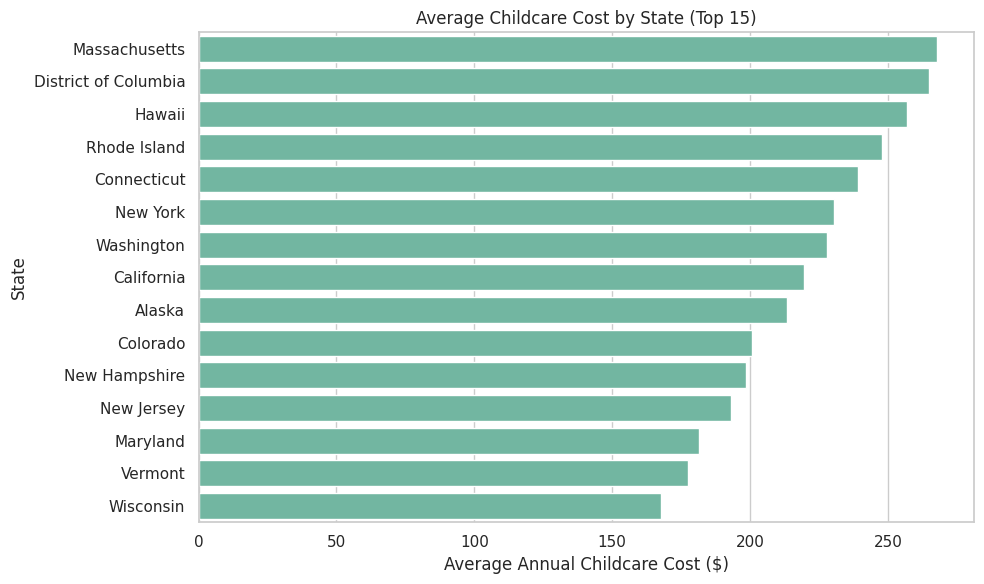

/tmp/ipykernel_14327/2142340252.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cost_burden.values, y=cost_burden.index, palette="flare")


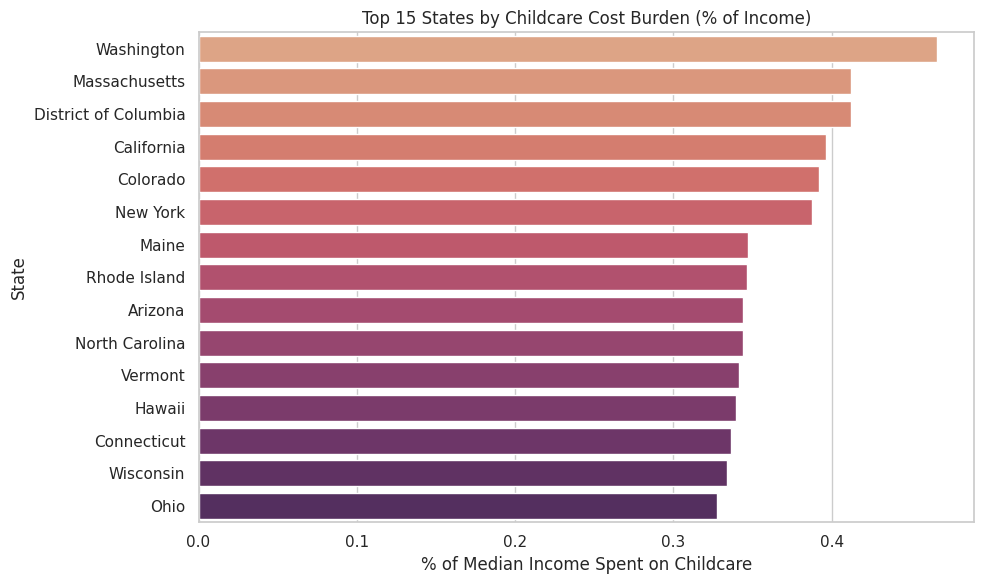

In [11]:
# ===========================================
# Childcare Costs, Poverty & Employment Visualization Dashboard
# ===========================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load and prepare data ---

# Basic cleanup
df = df.dropna(subset=["MHI", "ME", "PR_P", "FLFPR_20to64", "MCInfant", "MCToddler", "MCPreschool"])

# Calculate average childcare cost across age groups
df["AvgChildcareCost"] = df[["MCInfant", "MCToddler", "MCPreschool"]].mean(axis=1)

# Cost as a percentage of median income
df["CostPctIncome"] = (df["AvgChildcareCost"] / df["MHI"]) * 100

# Set consistent visual style
sns.set(style="whitegrid", palette="Set2")

# ===========================================
# 1. Average Childcare Cost by State
# ===========================================
plt.figure(figsize=(10,6))
avg_cost = df.groupby("State_Name")["AvgChildcareCost"].mean().sort_values(ascending=False).head(15)
sns.barplot(x=avg_cost.values, y=avg_cost.index)
plt.title("Average Childcare Cost by State (Top 15)")
plt.xlabel("Average Annual Childcare Cost ($)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# ===========================================
# 3. Childcare Cost as % of Income by State
# ===========================================
cost_burden = df.groupby("State_Name")["CostPctIncome"].mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=cost_burden.values, y=cost_burden.index, palette="flare")
plt.title("Top 15 States by Childcare Cost Burden (% of Income)")
plt.xlabel("% of Median Income Spent on Childcare")
plt.ylabel("State")
plt.tight_layout()
plt.show()


In [12]:
short_name_long_name = {
    'State_Name': 'State Name',
    'County_Name': 'County Name',
    'StudyYear': 'Study Year',
    'Households': 'Number of Households',
    
    'MCSA': 'Weekly full-time median price charged for Center-Based Care for school-age children',
    'MFCCSA': 'Weekly full-time median price charged for Family Childcare (home-based) for school-age children',


    'UNR_16':'Unemployment 16 & Older',
    'FUNR_16':'Female Unemployment 16 & Older',
    'MUNR_16':'Male Unemployment 16 & Older',

    'TotalPop':'Total Population',
    
    'UNR_20to64':'Unemployment 20-64 Year Olds',
    'PR_F':'Poverty Rate Families',
    'MHI_2018':'Median Household Income (2018 Dollars)',
    'OneRace_W':'Whites',
    'OneRace_B':'Blacks',
    'OneRace_H':'Hispanic',
    'OneRace_A':'Asian',

    'H_Under6_BothWork':'Households with children under 6 with both parents working',
    'H_6to17_BothWork':'Households with children between 6-17 with both parents working',

    'H_Under6_SingleM':'Households with children under 6 with single mom',
    'MCInfant':'Full Time Median Price for Infant (0 to 23 months) Care',
    'MCToddler':'Full Time Median Price for Toddler (24 to 35 months) Care',
    'MCPreschool':'Full Time Median Price for PreSchool (36 to 54 months) Care',
}


In [13]:
# Filter `df` to only columns present in `short_name_long_name`, rename them to long names, and save to CSV.

# Determine which short names exist in the dataframe
cols_to_keep = [c for c in short_name_long_name.keys() if c in df.columns]

if not cols_to_keep:
    raise ValueError("None of the keys from short_name_long_name are present in df.columns")

# Subset and rename
renames = {k: v for k, v in short_name_long_name.items() if k in cols_to_keep}
renamed_df = df[cols_to_keep].copy()
renamed_df.rename(columns=renames, inplace=True)

# Report missing keys (if any)
missing_keys = [k for k in short_name_long_name.keys() if k not in df.columns]
if missing_keys:
    print(f"Warning: the following expected columns were not found in df and were skipped: {missing_keys}")

# Save next to the original Excel file
out_path = file_path.with_name(file_path.stem + "_renamed.csv")
renamed_df.to_csv(out_path, index=False, encoding="utf-8")
print(f"Saved renamed CSV ({renamed_df.shape}) to: {out_path}")

Saved renamed CSV ((23593, 23)) to: data_renamed.csv


In [14]:
# sample up to 300 random rows from the already-defined `renamed_df`
sample_n = min(len(renamed_df), 300)
renamed_sample = renamed_df.sample(n=sample_n, random_state=42)

# save as data_renamed_sample.csv next to the original Excel file
sample_out = file_path.with_name("data_renamed_sample.csv")
renamed_sample.to_csv(sample_out, index=False, encoding="utf-8")
print(f"Saved sample ({renamed_sample.shape}) to: {sample_out}")

Saved sample ((300, 23)) to: data_renamed_sample.csv
